## **1. Setting Up**
- Importing libraries 
- <span style="color:red">**Make own libraries that include the python files I require AND sort out directories issue**</span>

- Do the following to get adata in right format for analysis
    - pp.adatas
    - 


In [1]:
# Change working directory
import os
tissue_path = os.path.join(os.getcwd(), "TISSUE")
os.chdir(tissue_path)

# import packages
import tissue.main, tissue.downstream
import tissue.SpaGE.main as sp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objs as go
from plotly.subplots import make_subplots
import scanpy as sc
import anndata as ad
import scipy.stats as st
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import mean_squared_error
from sklearn.metrics import auc
import torch
from torch.nn.functional import softmax, cosine_similarity, sigmoid
import tangram as tg

## **2. Loading Datasets and Exploration**

In [2]:
# import os
# print(os.getcwd())
os.chdir('/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation')

RNAseq_adata = sc.read('/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/gene_data/ageing_rna_20250114.h5ad')

adata = sc.read('/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/gene_data/SHG101350_processed.h5ad')

In [ ]:
ADA

## **3. Data Pre-Processing and Training Gene Selection**

##### **1. Filtering to Remove Sub-Cortex from Dataset**
- Subcortical cells were excluded from the spatial transcriptomics data due to low gene throughput in the corresponding single-cell dataset, which compromises the reliability of gene imputation in this region.
- <span style="color:green">**This is a coronal section**</span>

In [4]:
# Cortex Filtering - remove other regions
# Coordinates
x = adata.obs['center_x'].values
y = adata.obs['center_y'].values

# Ellipse centre
x0 = np.median(x) - 100
y0 = np.median(y) + 450

# Ellipse semi-axes — tune these for your brain slice - can add outer if I want to extract a subcortical layer (two more a and b params)
a = 3300  
b = 2400

# # Define rectangular bounds - to remove the bottom bit
# remove_mask = (x > 2400) & (y < 7950)
# keep_mask = ~remove_mask

# Ellipse equations
# outer_ellipse = ((x - x0) / a_outer) ** 2 + ((y - y0) / b_outer) ** 2 < 1
inner_ellipse = ((x - x0) / a) ** 2 + ((y - y0) / b) ** 2 > 1 

# Cortex mask: in outer ellipse but not inner
cortex_mask = inner_ellipse 
adata = adata[cortex_mask, :].copy()


--- Quantitative Summary of Datasets ---

Explanation of UMIs: Unique Molecular Identifiers (UMIs) are short nucleotide 
sequences used to tag individual mRNA molecules before PCR amplification. 
Counting the unique UMIs, rather than all sequencing reads, allows for a more 
accurate quantification of the original number of transcripts, effectively 
removing amplification bias. Therefore, 'total UMI counts' represents the 
total number of captured mRNA molecules per cell or spot.
    

--- Spatial Data ---
Observations (Spots)     : 51,377.00
Genes                    : 300.00
Mean UMIs / Spot         : 454.13
Median UMIs / Spot       : 467.69
Std Dev of UMIs          : 54.46

--- Single-Cell Reference ---
Observations (Cells)     : 173,199.00
Genes                    : 19,957.00
Mean UMIs / Cell         : 4,006.20
Median UMIs / Cell       : 3,819.00
Std Dev of UMIs          : 1,676.91


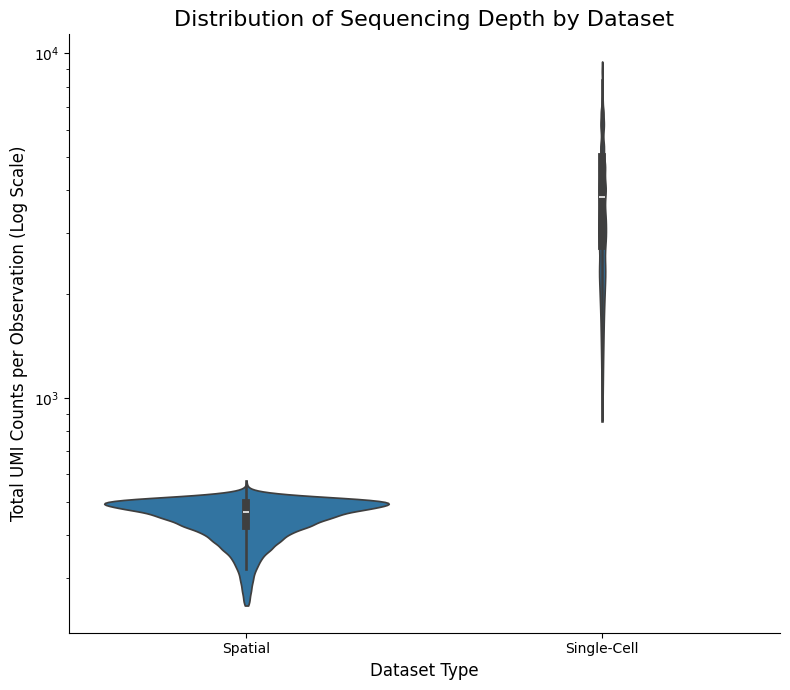

In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# --- Analysis: Dataset Summary and Sequencing Depth Comparison (Corrected) ---
# Assumes 'adata' (spatial) and 'RNAseq_adata' (single-cell) are loaded AnnData objects.

try:
    # 1. Get UMI counts per observation (cell or spot)
    # For spatial data, use the accurate pre-calculated 'transcript_count' column.
    if 'transcript_count' in adata.obs.columns:
        print("Using pre-calculated 'transcript_count' from adata.obs for spatial data.")
        spatial_counts = adata.obs['transcript_count'].values
    else:
        print("Warning: 'transcript_count' not found. Calculating from adata.X for spatial data.")
        spatial_counts = np.asarray(adata.X.sum(axis=1)).flatten()

    # For single-cell data, calculate from the matrix as its structure is unknown.
    sc_counts = np.asarray(RNAseq_adata.X.sum(axis=1)).flatten()

    # 2. Generate Textual Summary
    print("\n--- Quantitative Summary of Datasets ---")
    print("""
Explanation of UMIs: Unique Molecular Identifiers (UMIs) are short nucleotide 
sequences used to tag individual mRNA molecules before PCR amplification. 
Counting the unique UMIs, rather than all sequencing reads, allows for a more 
accurate quantification of the original number of transcripts, effectively 
removing amplification bias. Therefore, 'total UMI counts' represents the 
total number of captured mRNA molecules per cell or spot.
    """)
    
    summary_data = {
        "Spatial Data": {
            "Observations (Spots)": adata.n_obs,
            "Genes": adata.n_vars,
            "Mean UMIs / Spot": np.mean(spatial_counts),
            "Median UMIs / Spot": np.median(spatial_counts),
            "Std Dev of UMIs": np.std(spatial_counts)
        },
        "Single-Cell Reference": {
            "Observations (Cells)": RNAseq_adata.n_obs,
            "Genes": RNAseq_adata.n_vars,
            "Mean UMIs / Cell": np.mean(sc_counts),
            "Median UMIs / Cell": np.median(sc_counts),
            "Std Dev of UMIs": np.std(sc_counts)
        }
    }
    
    for name, stats in summary_data.items():
        print(f"\n--- {name} ---")
        for key, value in stats.items():
            print(f"{key:<25}: {value:,.2f}")

    # 3. Create a combined DataFrame for plotting
    plot_df = pd.DataFrame({
        'Total UMI Counts': np.concatenate([spatial_counts, sc_counts]),
        'Dataset': ['Spatial'] * len(spatial_counts) + ['Single-Cell'] * len(sc_counts)
    })

    # 4. Create the visualization
    plt.figure(figsize=(8, 7))
    ax = sns.violinplot(
        data=plot_df,
        x='Dataset',
        y='Total UMI Counts',
        cut=0, 
        inner='box'
    )
    
    # Use a log scale for better visualization of skewed distributions
    plt.yscale('log')
    
    ax.set_title('Distribution of Sequencing Depth by Dataset', fontsize=16)
    ax.set_xlabel('Dataset Type', fontsize=12)
    ax.set_ylabel('Total UMI Counts per Observation (Log Scale)', fontsize=12)
    
    sns.despine()
    plt.tight_layout()
    plt.show()

except NameError as e:
    print(f"Execution failed. A required variable is not defined: {e}.")
    print("Please ensure 'adata' and 'RNAseq_adata' are loaded in your environment.")
except Exception as e:
    print(f"An unexpected error occurred: {e}")

#END

--- Spatial Distribution of Filtered Cortex Spots ---
Visualizing the spatial layout of the filtered cortical region.
Number of spots after filtering: 51377
X-coordinate range: 467.71 to 9464.82
Y-coordinate range: 216.27 to 6388.85


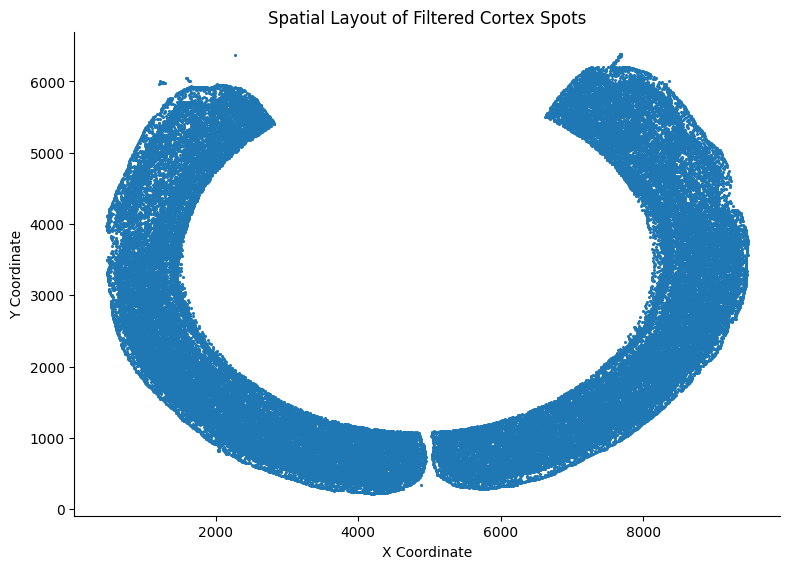

In [5]:
# --- Analysis: Visualize Filtered Spatial Coordinates ---
# Assumes 'adata' is a filtered AnnData object from the previous step.

# 1. Extract coordinates for plotting
coords_df = adata.obs[['center_x', 'center_y']].copy()
num_spots = len(coords_df)

# 2. Generate textual output
print("--- Spatial Distribution of Filtered Cortex Spots ---")
print(f"Visualizing the spatial layout of the filtered cortical region.")
print(f"Number of spots after filtering: {num_spots}")
print(f"X-coordinate range: {coords_df['center_x'].min():.2f} to {coords_df['center_x'].max():.2f}")
print(f"Y-coordinate range: {coords_df['center_y'].min():.2f} to {coords_df['center_y'].max():.2f}")

# 3. Create the scatter plot
plt.figure(figsize=(8, 8))
ax = sns.scatterplot(
    data=coords_df,
    x='center_x',
    y='center_y',
    s=5,  # Small marker size for dense spots
    linewidth=0
)

# 4. Formatting
ax.set_title('Spatial Layout of Filtered Cortex Spots')
ax.set_xlabel('X Coordinate')
ax.set_ylabel('Y Coordinate')
ax.set_aspect('equal', adjustable='box')
sns.despine()
plt.tight_layout()
plt.show()

#END

##### **2. Pre-Processing**
- **Normalises** gene counts using log 1p normalisation 
- Converts gene names to **lower** case  
- Filter for intersecting genes

In [4]:
# make genes lowercase
adata.var_names = [x.lower() for x in adata.var_names]
RNAseq_adata.var_names = [x.lower() for x in RNAseq_adata.var_names]

# preprocess RNAseq data
tissue.main.preprocess_data(RNAseq_adata, standardize=False, normalize=True)
tissue.main.preprocess_data(adata, standardize=False, normalize=True)

# subset spatial data into shared genes (the tutorial does not include the extra line that I added)
gene_names = np.intersect1d(adata.var_names, RNAseq_adata.var_names)
adata = adata[:, gene_names].copy()
RNAseq_adata = RNAseq_adata[:, gene_names].copy()


# annotate gene sparsity in both datasets
def annotate_gene_sparsity(adata):
    """
    Annotates gene sparsity in given Anndatas. 
    Update given Anndata by creating `var` "sparsity" field with gene_sparsity (1 - % non-zero observations).

    Args:
        adata (Anndata): single cell or spatial data.

    Returns:
        None
    """
    mask = adata.X != 0
    gene_sparsity = np.sum(mask, axis=0) / adata.n_obs
    gene_sparsity = np.asarray(gene_sparsity)
    gene_sparsity = 1 - np.reshape(gene_sparsity, (-1,))
    adata.var["sparsity"] = gene_sparsity

annotate_gene_sparsity(adata)
annotate_gene_sparsity(RNAseq_adata)

In [7]:
gene_names

array(['acin1', 'acsl4', 'actg1', 'actn4', 'add2', 'alcam', 'aldoc',
       'amigo2', 'ankrd6', 'apc', 'arc', 'arglu1', 'atg5', 'atg7', 'atn1',
       'atp2b1', 'atp6v0a1', 'atp6v0d1', 'baiap2', 'baz2a', 'bcl11b',
       'bmerb1', 'bnip3', 'bod1l', 'brd4', 'brd9', 'bzw1', 'cacnb3',
       'cadps2', 'calb1', 'calb2', 'camk2n1', 'car4', 'cck', 'ccn2',
       'ccn3', 'ccni', 'ccnl2', 'cd46', 'cdh13', 'cdh9', 'cdk11b',
       'cdkn1a', 'cdkn2a', 'cdkn2d', 'cfap97', 'chd4', 'chodl', 'chrm2',
       'cirbp', 'clk2', 'clmp', 'cnr1', 'col23a1', 'col25a1', 'cort',
       'cox4i1', 'cox6a2', 'cplx2', 'cpne2', 'cpne5', 'cpne7', 'crh',
       'crhbp', 'crispld2', 'cryab', 'crym', 'ctsd', 'cxcl14', 'dcn',
       'dctn5', 'ddit4l', 'dgkd', 'diaph1', 'dip2a', 'dkkl1', 'dlg5',
       'dot1l', 'dut', 'ehmt1', 'ehmt2', 'eif3f', 'eif4a2', 'enpp2',
       'epg5', 'fam216a', 'fbxo22', 'fezf2', 'fndc5', 'fos', 'fryl',
       'fubp1', 'gabrb3', 'gabrd', 'gabrg1', 'gad1', 'gda', 'gdpd1',
       'gigyf1', 'gig

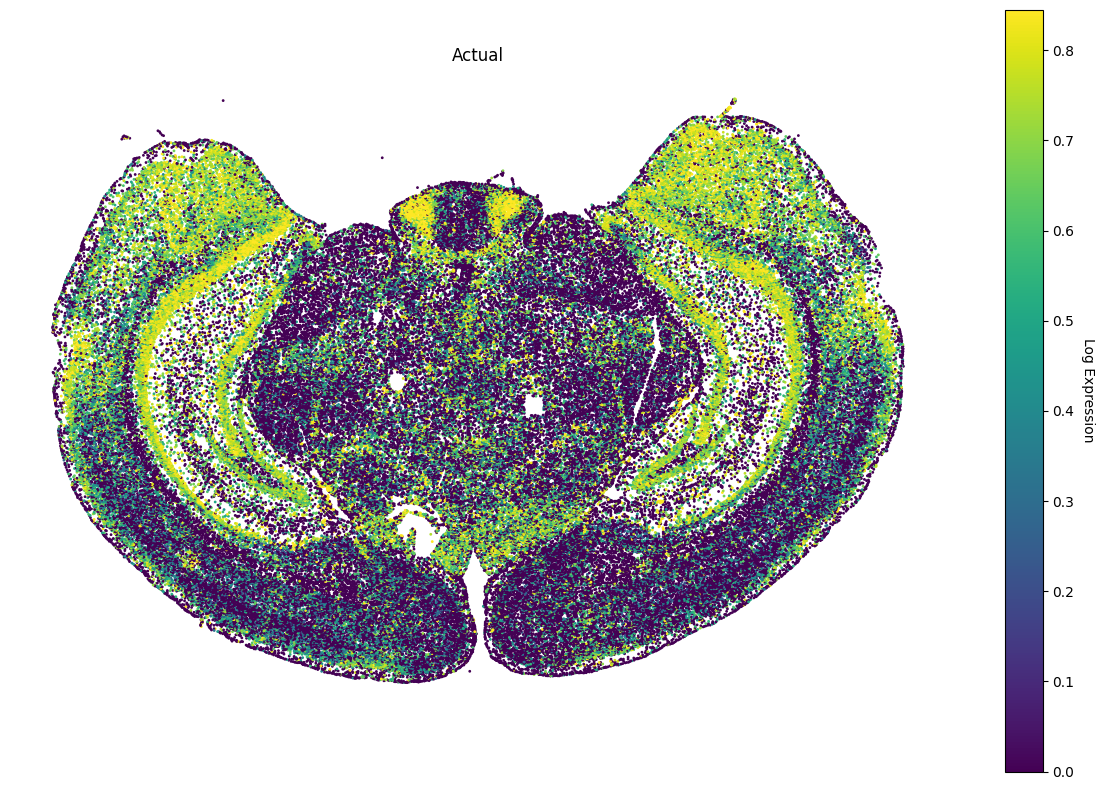

In [19]:
import matplotlib.pyplot as plt
import numpy as np

target_gene = "nos1"
target_expn = adata[:, target_gene].X.copy()

# Clean and transform expression values
cmap = target_expn
cmap[cmap < 0] = 0
cmap = np.log1p(cmap)
cmap[cmap > np.percentile(cmap, 95)] = np.percentile(cmap, 95)

# Plot
fig, ax1 = plt.subplots(1, figsize=(12, 8))
ax1.axis('off')
ax1.set_aspect('equal')

im = ax1.scatter(
    adata.obs['center_x'], 
    adata.obs['center_y'], 
    s=1, 
    c=cmap, 
    rasterized=True
)

ax1.set_title('Actual', fontsize=12)

# Colourbar
cbar = fig.colorbar(im, ax=ax1)
cbar.ax.get_yaxis().labelpad = 15
cbar.ax.set_ylabel('Log Expression', rotation=270)

plt.tight_layout()
plt.show()



##### **3. Tangram-Specific Pre-Processing and Functions**
- <span style="color:red">**There is some overhead I could and should remove - the lower case and other stuff - here and in the Tangram LOOC loop**</span>
1. Stores training genes for both datasets in uns -  <span style="color:red">**Could train using only highly variable genes - more training genes does not guarantee improvement - see main tangram training regimen**</span>
2. Tangram impute finds mapping between cells in RNA_seq and spatial data based on shared genes 
    * The efficient **"clusters" method** is used averaging expression across cells in single cell data
    * Each **subclass cluster** is assigned a probability for being a spatial transcriptomics cell
    * This is used to **predict** the expression of the unmeasured spatial genes


In [ ]:
def tangram_pp (spatial_adata, RNAseq_adata, use_stored_clusters = True, **kwargs):
    '''
    Pre-processes RNA sequencing data by clustering it using Leiden clustering and filtering for shared genes
    
    '''
    
    if use_stored_clusters != True:
        # clustering and preprocessing - new
        RNAseq_adata_label = RNAseq_adata.copy()
        sc.pp.highly_variable_genes(RNAseq_adata_label)
        RNAseq_adata_label = RNAseq_adata[:, RNAseq_adata_label.var.highly_variable].copy()
        sc.pp.scale(RNAseq_adata_label, max_value=10)
        sc.tl.pca(RNAseq_adata_label)
        sc.pp.neighbors(RNAseq_adata_label)
        sc.tl.leiden(RNAseq_adata_label, resolution = 0.5)
        RNAseq_adata.obs['leiden'] = RNAseq_adata_label.obs.leiden
        del RNAseq_adata_label
        tg.pp_adatas(RNAseq_adata, spatial_adata) # genes=None default using all genes shared between two data
    else:
        tg.pp_adatas(RNAseq_adata, spatial_adata) # genes=None default using all genes shared between two data
    

def tangram_impute (spatial_adata, RNAseq_adata, genes_to_predict, use_stored_clusters = True, **kwargs):
    '''
    Run Tangram gene imputation (positioning) using the more efficient cluster-level approach with Leiden clustering
    
    See predict_gene_expression() for details on arguments
    '''

    # gene projection onto spatial
    if use_stored_clusters != True:
        ad_map = tg.map_cells_to_space(RNAseq_adata, spatial_adata, cv_train_genes = spatial_adata.uns['training_genes'], mode='clusters', cluster_label='leiden', density_prior='rna_count_based', verbose=False)
        ad_ge = tg.project_genes(ad_map, RNAseq_adata, cluster_label='leiden')
    else:
        training_genes = spatial_adata.uns['training_genes']
        valid_genes = [g for g in training_genes if g in spatial_adata.var_names and g in RNAseq_adata.var_names]


        # Then call Tangram with only valid genes
        ad_map = tg.map_cells_to_space(
            RNAseq_adata,
            spatial_adata,
            cv_train_genes=valid_genes,
            mode='clusters',
            cluster_label='subclass_name',
            density_prior='uniform',
            verbose=False
        )

        ad_ge = tg.project_genes(ad_map, RNAseq_adata, cluster_label='subclass_name')
    
    predicted_expression = pd.DataFrame(ad_ge[:,genes_to_predict].X, index=ad_ge[:,genes_to_predict].obs_names, columns=ad_ge[:,genes_to_predict].var_names)
    
    return(predicted_expression)


## **4. LOO Cross-Validation**

* <span style="color:red">**SpaGE function standardises data in addition to normalisation, I think Tangram just takes log-normalised data (something to check)**</span>
* <span style="color:red">**Can save computing time by scaling SpaGE just one time, there is no reason to repeat it each time I loop through**</span>

In [7]:
def predict_gene_expression_one_gene(spatial_adata, RNAseq_adata, gene, method="spage", **kwargs):
    """
    Predicts expression of a single gene using spatial and RNAseq data
    by masking the gene in the spatial data.

    Parameters:
    -----------
    spatial_adata : AnnData
        Spatial data with measured gene expression (scaled if SpaGE used)
    RNAseq_adata : AnnData
        Reference RNAseq data (scaled if SpaGE used)
    gene : str
        The gene to leave out and predict
    method : str
        Imputation method to use: "spage", "knn", "gimvi", "tangram"
    **kwargs :
        Additional arguments passed to the imputation function

    Returns:
    --------
    pd.Series of predicted expression values indexed by spatial_adata.obs_names
    """
    gene = gene.lower()
    spatial_adata.var_names = [v.lower() for v in spatial_adata.var_names]
    RNAseq_adata.var_names = [v.lower() for v in RNAseq_adata.var_names]

    if gene not in spatial_adata.var_names or gene not in RNAseq_adata.var_names:
        raise ValueError(f"Gene '{gene}' must exist in both spatial and RNAseq data.")

    masked = spatial_adata[:, spatial_adata.var_names != gene].copy()

    if method == "spage":
        # Mask the gene from spatial data
        pred = tissue.main.spage_impute(masked, RNAseq_adata, genes_to_predict=[gene], **kwargs)
    elif method == "tangram":
        pred = tangram_impute(masked, RNAseq_adata, genes_to_predict=[gene],**kwargs)
    else:
        raise ValueError(f"Method '{method}' not recognised.")

    return pred[gene].rename(gene)


##### **2. Tangram LOOC Loop**
- First step stores training genes in unstructured data (all 464 genes used)
- <span style="color:red">**I think I should present the option to remove some training genes - use the high variability thing - for later**</span>
- <span style="color:red">**remove more overhead the shared genes filter has been applied before and I use something similar in the predict_gene_expression function too...**</span>

In [ ]:
# Store training genes in unstructured data
tangram_pp(adata, RNAseq_adata, use_stored_clusters = True)

# Get shared genes between spatial and RNAseq
shared_genes = [g for g in adata.var_names if g in RNAseq_adata.var_names]

# Store predictions
all_preds = []

for i, gene in enumerate(shared_genes):
    print(f"🔁 Predicting gene: {gene} ({i+1}/{len(shared_genes)})")
    pred_series = predict_gene_expression_one_gene(adata, RNAseq_adata, gene, method="tangram")
    all_preds.append(pred_series)

# Combine into DataFrame
predicted_expression = pd.concat(all_preds, axis=1)
predicted_expression.index = adata.obs_names

##### **3. SpaGE LOOC Loop**

- **<span style="color:green">Scaling is necessary for SpaGE, mentioned in their preprocessing<span style="color:green">**

Using just normalised data

In [8]:
# Get shared genes between spatial and RNAseq
shared_genes = [g for g in adata.var_names if g in RNAseq_adata.var_names]

# Store predictions
all_preds = []

for i, gene in enumerate(shared_genes):
    print(f"🔁 Predicting gene: {gene} ({i+1}/{len(shared_genes)})")
    pred_series = predict_gene_expression_one_gene(adata, RNAseq_adata, gene, method="spage", n_pv=20)
    all_preds.append(pred_series)

# Combine into DataFrame
predicted_expression = pd.concat(all_preds, axis=1)
predicted_expression.index = adata.obs_names

🔁 Predicting gene: acin1 (1/296)
🔁 Predicting gene: acsl4 (2/296)
🔁 Predicting gene: actg1 (3/296)
🔁 Predicting gene: actn4 (4/296)
🔁 Predicting gene: add2 (5/296)
🔁 Predicting gene: alcam (6/296)
🔁 Predicting gene: aldoc (7/296)
🔁 Predicting gene: amigo2 (8/296)
🔁 Predicting gene: ankrd6 (9/296)
🔁 Predicting gene: apc (10/296)
🔁 Predicting gene: arc (11/296)
🔁 Predicting gene: arglu1 (12/296)
🔁 Predicting gene: atg5 (13/296)
🔁 Predicting gene: atg7 (14/296)
🔁 Predicting gene: atn1 (15/296)
🔁 Predicting gene: atp2b1 (16/296)
🔁 Predicting gene: atp6v0a1 (17/296)
🔁 Predicting gene: atp6v0d1 (18/296)
🔁 Predicting gene: baiap2 (19/296)
🔁 Predicting gene: baz2a (20/296)
🔁 Predicting gene: bcl11b (21/296)
🔁 Predicting gene: bmerb1 (22/296)
🔁 Predicting gene: bnip3 (23/296)
🔁 Predicting gene: bod1l (24/296)
🔁 Predicting gene: brd4 (25/296)
🔁 Predicting gene: brd9 (26/296)
🔁 Predicting gene: bzw1 (27/296)
🔁 Predicting gene: cacnb3 (28/296)
🔁 Predicting gene: cadps2 (29/296)
🔁 Predicting gene: 

In [9]:
predicted_expression.to_csv('/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/spage_preds_d2.csv', index=True)

In [10]:
predicted_expression

,acin1,acsl4,actg1,actn4,add2,alcam,aldoc,amigo2,ankrd6,apc,...,wfs1,wsb1,xpc,ybx1,yjefn3,zbtb20,zbtb38,zc3h18,zcchc12,zfp777
cell,,,,,,,,,,,,,,,,,,,,,
1818618800005100006,0.258880,0.143591,0.088438,0.176692,0.016202,0.938225,0.082322,0.016365,0.097958,0.708716,...,0.000000,0.361590,0.026250,0.068988,0.0,2.022700,0.080141,0.033428,0.000000,0.090599
1818618800005100007,0.254727,0.064244,0.122085,0.154571,0.028101,0.563213,0.000000,0.000000,0.113532,0.748895,...,0.025883,0.502666,0.072408,0.024205,0.0,2.281369,0.020146,0.054460,0.019786,0.030485
1818618800005100008,0.135165,0.073223,0.200790,0.111312,0.031801,0.827799,0.138489,0.000000,0.083302,0.474415,...,0.000000,0.237076,0.034182,0.074600,0.0,2.176760,0.053426,0.041338,0.000000,0.022646
1818618800005100011,0.356607,0.053822,0.261060,0.117775,0.069090,1.033555,0.080763,0.000000,0.062183,0.700690,...,0.000000,0.423788,0.000000,0.122157,0.0,2.088947,0.188914,0.026904,0.000000,0.030357
1818618800005100012,0.339005,0.142212,0.173501,0.126767,0.035336,1.288441,0.107241,0.000000,0.076441,0.717738,...,0.016263,0.460392,0.048865,0.182503,0.0,2.199327,0.111200,0.109240,0.000000,0.102816
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1818618800254200022,0.280376,0.138572,0.219107,0.080316,0.027917,0.422872,0.141226,0.000000,0.000000,0.309965,...,0.022756,0.293043,0.000000,0.141767,0.0,2.053603,0.094541,0.033658,0.000000,0.000000
1818618800274100077,0.300851,0.145667,0.257245,0.142809,0.056325,1.875340,0.060821,0.000000,0.031821,0.732858,...,0.046251,0.227397,0.032425,0.072791,0.0,2.453728,0.051244,0.080367,0.019774,0.104641
1818618800274100082,0.222045,0.094758,0.194468,0.119169,0.064084,1.618461,0.156674,0.000000,0.064286,0.563793,...,0.065315,0.232180,0.103555,0.155756,0.0,2.566176,0.080125,0.139909,0.000000,0.041418


In [11]:
RNAseq_adata.write('/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/RNA_seq_adata_processed_d2.h5ad')
adata.write('/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/adata_processed_d2.h5ad')

## **5. LOOC Results and Analysis**

##### **1. Load in predictions**
- Format: cells (numbers) x genes (names LC)

In [10]:
spage_preds = pd.read_csv('/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/tissue_spage.csv', index_col=0)

In [11]:
tangram_preds = pd.read_csv('/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation_Comparison/tissue_tangram_20250521.csv', index_col=0)

In [14]:
adata

AnnData object with n_obs × n_vars = 19441 × 464
    obs: 'EntityID', 'fov', 'volume', 'center_x', 'center_y', 'min_x', 'min_y', 'max_x', 'max_y', 'anisotropy', 'transcript_count', 'perimeter_area_ratio', 'solidity', 'cell_id', 'class_label', 'class_name', 'class_bootstrapping_probability', 'subclass_label', 'subclass_name', 'subclass_bootstrapping_probability', 'supertype_label', 'supertype_name', 'supertype_bootstrapping_probability', 'cluster_label', 'cluster_name', 'cluster_alias', 'cluster_bootstrapping_probability'
    var: 'sparsity'
    uns: 'log1p'

In [10]:
actual_gene_expression = pd.DataFrame(data=st.zscore(adata.X,axis=0),
                                   index = adata.obs_names,columns=adata.var_names)

In [11]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

##### **1. SpaGE Analysis**

In [ ]:
# Step 1: Get common genes
common_genes = spage_preds.columns.intersection(actual_gene_expression.columns)

# Step 2: Compute Pearson and Spearman correlations for each gene
results = {}
for gene in common_genes:
    x = spage_preds[gene]
    y = actual_gene_expression[gene]
    pearson_r, _ = st.pearsonr(x, y)
    spearman_r, _ = st.spearmanr(x, y)
    rmse_val = rmse(y, x)

    # Cosine similarity
    norm_x = np.linalg.norm(x)
    norm_y = np.linalg.norm(y)
    cosine_sim = np.nan if norm_x == 0 or norm_y == 0 else np.dot(x, y) / (norm_x * norm_y)

    results[gene] = {
        'pearson_r': pearson_r,
        'spearman_r': spearman_r,
        'RMSE': rmse_val,
        'cosine_sim': cosine_sim,
    }

# Step 3: Convert to DataFrame
spage_metrics_df = pd.DataFrame.from_dict(results, orient='index')

In [ ]:
# Extract sparsity as DataFrames with explicit column names
df_sparsity_sp = pd.DataFrame(
    adata[:, common_genes].var["sparsity"]
).rename(columns={"sparsity": "sparsity_sp"})

df_sparsity_sc = pd.DataFrame(
    RNAseq_adata[:, common_genes].var["sparsity"]
).rename(columns={"sparsity": "sparsity_sc"})

# Merge the two sparsity DataFrames
df_sparsity = df_sparsity_sp.merge(
    df_sparsity_sc, left_index=True, right_index=True
)

# Calculate the difference
df_sparsity["sparsity_diff"] = np.abs(df_sparsity["sparsity_sp"] - df_sparsity["sparsity_sc"])

# Merge with the existing metrics
gene_metrics_df = spage_metrics_df.merge(
    df_sparsity, left_index=True, right_index=True
)

In [14]:
def plot_training_scores(metrics_df, bins=10, alpha=0.7):
    """
    Plots the 4-panel training diagnosis plot using the metrics_df.

    Args:
        metrics_df (pd.DataFrame): Must contain columns: 'train_score', 'sparsity_sc', 'sparsity_sp', 'sparsity_diff'.
        bins (int or string): Number of histogram bins. Default is 10.
        alpha (float): Opacity of scatter plot points. Default is 0.7.

    Returns:
        None
    """
    import matplotlib.pyplot as plt
    import seaborn as sns

    fig, axs = plt.subplots(1, 4, figsize=(14, 3), sharey=True)
    axs_f = axs.flatten()

    axs_f[0].set_ylim([0.0, 1.0])
    for i in range(1, len(axs_f)):
        axs_f[i].set_xlim([0.0, 1.0])
        axs_f[i].set_ylim([0.0, 1.0])

    sns.histplot(data=metrics_df, y="pearson_r", bins=bins, ax=axs_f[0], color="coral")
    axs_f[0].set_title("Train score distribution")

    axs_f[1].set_title("Score vs sparsity (single-cell)")
    sns.scatterplot(
        data=metrics_df,
        y="pearson_r",
        x="sparsity_sc",
        ax=axs_f[1],
        alpha=alpha,
        color="coral",
    )

    axs_f[2].set_title("Score vs sparsity (spatial)")
    sns.scatterplot(
        data=metrics_df,
        y="pearson_r",
        x="sparsity_sp",
        ax=axs_f[2],
        alpha=alpha,
        color="coral",
    )

    axs_f[3].set_title("Score vs sparsity (sp - sc)")
    sns.scatterplot(
        data=metrics_df,
        y="pearson_r",
        x="sparsity_diff",
        ax=axs_f[3],
        alpha=alpha,
        color="coral",
    )

    plt.tight_layout()

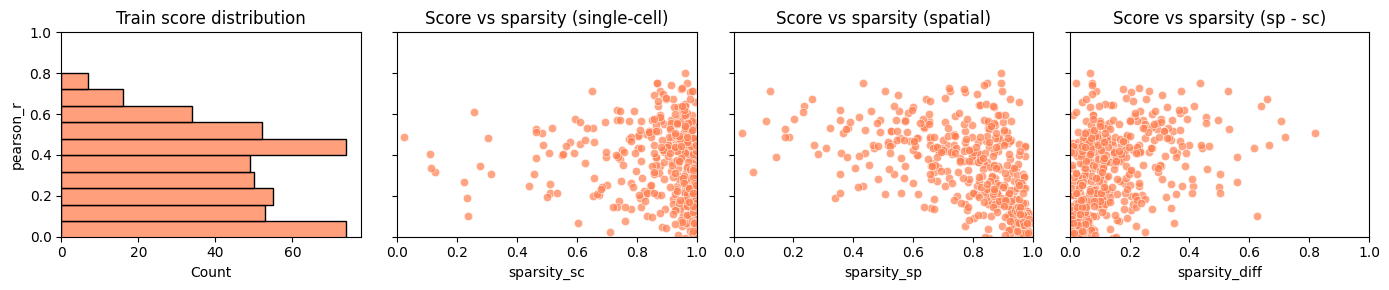

In [15]:
plot_training_scores(gene_metrics_df)

In [16]:
def eval_metric(df_metrics):
    """
    Compute metrics on given test_genes set for evaluation
    
    Args:
        df_all_genes (Pandas dataframe): returned by compare_spatial_geneexp(adata_ge, adata_sp); 
        test_genes (list): list of test genes, if not given, test_genes will be set to genes where 'is_training' field is False

    Returns:      
        dict with values of each evaluation metric ("avg_test_score", "avg_train_score", "auc_score"), 
        tuple of auc fitted coordinates and raw coordinates(test_score vs. sparsity_sp coordinates)
    """

    shared_genes = df_metrics.index

    # calculate:
    test_gene_scores = df_metrics.loc[shared_genes]["pearson_r"]
    test_gene_sparsity_sp = df_metrics.loc[shared_genes]["sparsity_sp"]
    test_score_avg = test_gene_scores.mean()

    # sp sparsity weighted score - metric across all genes
    test_score_sps_sp_g2 = np.sum(
        (test_gene_scores * (1 - test_gene_sparsity_sp))
        / (1 - test_gene_sparsity_sp).sum()
    )

    # tm metric
    # Fit polynomial'
    xs = list(test_gene_sparsity_sp)   # x-axis
    ys = list(test_gene_scores)        # y-axis
    pol_deg = 2
    pol_cs = np.polyfit(xs, ys, pol_deg)  # Fit y = f(x)
    pol = np.poly1d(pol_cs)
    # Generate fitted values
    pol_xs = np.linspace(0, 1, 10)
    pol_ys = [pol(x) for x in pol_xs]
    # Clip y values to maximum of 1
    pol_ys = [min(y, 1) for y in pol_ys]

    # Constrains y values to 1 or less
    if pol_ys[0] > 1:
        pol_ys[0] = 1

    # Try to add a root if the polynomial crosses y = 0 within [0,1]
    roots = pol.r
    root = None
    for r in roots:
        if np.isreal(r) and 0 <= r <= 1:
            root = np.real(r)
            break
    if root is not None:
        pol_xs = np.append(pol_xs, root)
        pol_ys = np.append(pol_ys, 0)


    # Add right endpoint (x=1) explicitly
    pol_xs = np.append(pol_xs, 1)
    pol_ys = np.append(pol_ys, pol(1))

    # Filter out any x or y values outside [0, 1]
    filtered = [(x, y) for x, y in zip(pol_xs, pol_ys) if 0 <= x <= 1 and 0 <= y <= 1]
    pol_xs, pol_ys = zip(*sorted(filtered)) if filtered else ([], [])

    # Compute are under the curve of polynomial
    auc_test_score = np.real(auc(pol_xs, pol_ys))

    metric_dict = {
        "avg_test_score": test_score_avg,
        "sp_sparsity_score": test_score_sps_sp_g2,
        "auc_score": auc_test_score,
    }

    auc_coordinates = ((pol_xs, pol_ys), (xs, ys))

    return metric_dict, auc_coordinates


In [17]:
def plot_auc(df_all_genes, test_genes=None):
    """
        Plots auc curve which is used to evaluate model performance.
    
    Args:
        df_all_genes (Pandas dataframe): returned by compare_spatial_geneexp(adata_ge, adata_sp); 
        test_genes (list): list of test genes, if not given, test_genes will be set to genes where 'is_training' field is False

    Returns:
        None
    """
    metric_dict, ((pol_xs, pol_ys), (xs, ys)) = eval_metric(df_all_genes)
    
    fig = plt.figure()
    plt.figure(figsize=(6, 5))

    plt.plot(pol_xs, pol_ys, c='r')
    sns.scatterplot(x=xs, y=ys, alpha=0.5, edgecolors='face')
        
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.0])
    plt.gca().set_aspect(.5)
    plt.xlabel('score')
    plt.ylabel('spatial sparsity')
    plt.tick_params(axis='both', labelsize=8)
    plt.title('Prediction on test transcriptome')
    
    textstr = 'auc_score={}'.format(np.round(metric_dict['auc_score'], 3))
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.3)
    # place a text box in upper left in axes coords
    plt.text(0.03, 0.1, textstr, fontsize=11, verticalalignment='top', bbox=props);

<Figure size 640x480 with 0 Axes>

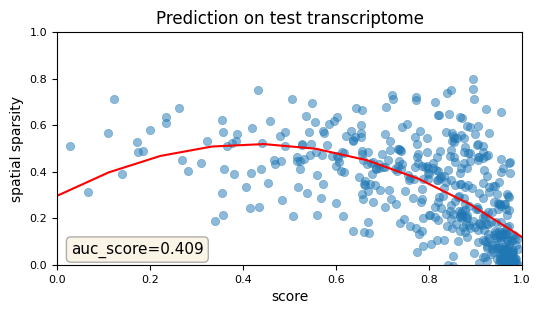

In [373]:
plot_auc(gene_metrics_df)

##### **2. Tangram Analysis**

In [18]:
# Step 1: Get common genes
common_genes = tangram_preds.columns.intersection(actual_gene_expression.columns)

# Step 2: Compute Pearson and Spearman correlations for each gene
results = {}
for gene in common_genes:
    x = tangram_preds[gene]
    y = actual_gene_expression[gene]
    pearson_r, _ = st.pearsonr(x, y)
    spearman_r, _ = st.spearmanr(x, y)
    rmse_val = rmse(y, x)

    # Cosine similarity
    norm_x = np.linalg.norm(x)
    norm_y = np.linalg.norm(y)
    cosine_sim = np.nan if norm_x == 0 or norm_y == 0 else np.dot(x, y) / (norm_x * norm_y)

    results[gene] = {
        'pearson_r': pearson_r,
        'spearman_r': spearman_r,
        'RMSE': rmse_val,
        'cosine_sim': cosine_sim,
    }

# Step 3: Convert to DataFrame
tangram_metrics_df = pd.DataFrame.from_dict(results, orient='index')

In [19]:

# Merge with the existing metrics
tangram_gene_metrics_df = tangram_metrics_df.merge(
    df_sparsity, left_index=True, right_index=True
)

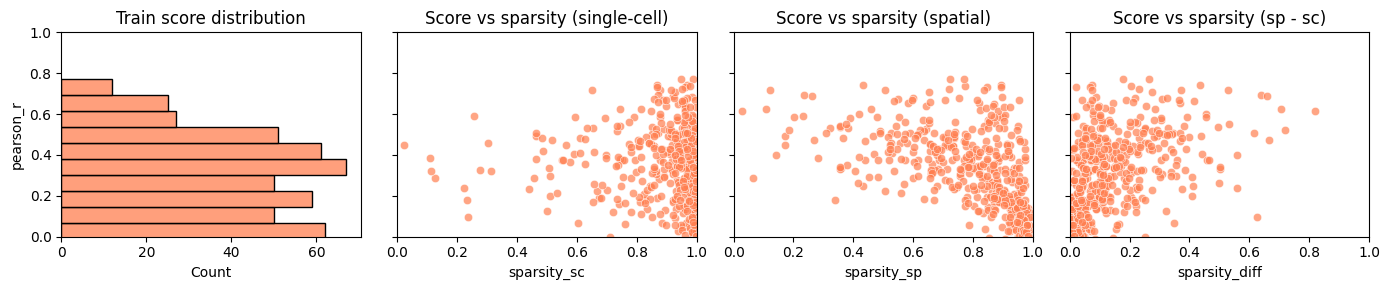

In [20]:
plot_training_scores(tangram_gene_metrics_df)

<Figure size 640x480 with 0 Axes>

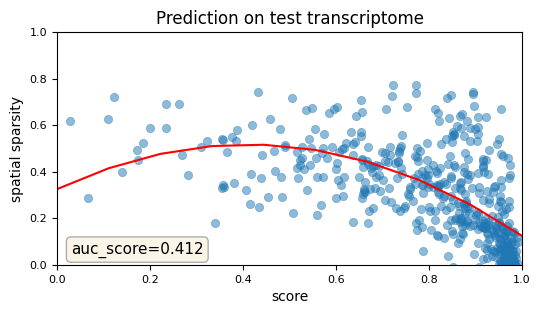

In [21]:
plot_auc(tangram_gene_metrics_df)

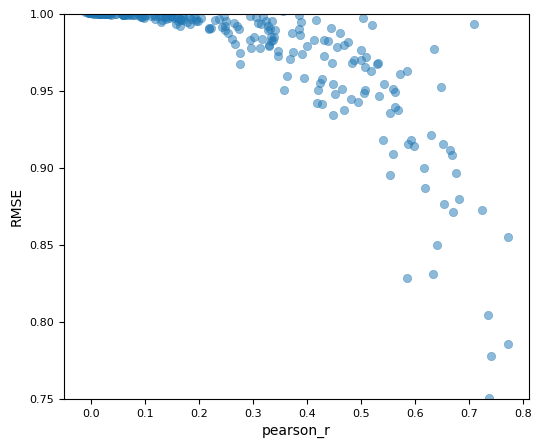

In [22]:
plt.figure(figsize=(6, 5))

# 
sns.scatterplot(x=tangram_gene_metrics_df['pearson_r'], y=tangram_gene_metrics_df['RMSE'], alpha=0.5, edgecolors='face')
    
# plt.xlim([0.0, 0.6])
plt.ylim([0.75, 1])
# plt.gca().set_aspect(.5)
# plt.xlabel('Cosine similarity')
# plt.ylabel('Spearman Rank')
plt.tick_params(axis='both', labelsize=8)

In [23]:
# Top 5 genes with highest Pearson r
top = tangram_gene_metrics_df.sort_values(by="pearson_r", ascending=False)[0:20]

# Bottom 5 genes with lowest Pearson r
bottom = tangram_gene_metrics_df.sort_values(by="spearman_r", ascending=True).head()

print(top)


         pearson_r  spearman_r      RMSE  cosine_sim  sparsity_sp  \
cldn5     0.772124    0.327433  0.785288    0.706148     0.722648   
plekhg3   0.771625    0.407276  0.854887    0.538563     0.770999   
atp13a5   0.741457    0.158888  0.777579    0.681498     0.894244   
gad1      0.740909    0.385105  1.275899    0.464700     0.431974   
flt1      0.737693    0.329698  0.750623    0.668089     0.772800   
cspg4     0.734731    0.296487  0.804096    0.606386     0.894090   
mog       0.730582    0.344835  2.266562    0.550798     0.846716   
slc32a1   0.723597    0.398223  0.872623    0.489960     0.719665   
slc17a7   0.719238    0.741833  2.823157    0.286786     0.122113   
bcan      0.718238    0.462518  1.402393    0.439679     0.504449   
opalin    0.718101    0.346477  1.313944    0.533556     0.838383   
olig1     0.710248    0.408415  0.993116    0.440700     0.653619   
chrm1     0.691334    0.680081  1.111730    0.281077     0.234196   
mfge8     0.689646    0.455789  1.

In [24]:
tangram_preds.index = adata.obs_names
adata.obsm['tangram_predictions'] = tangram_preds

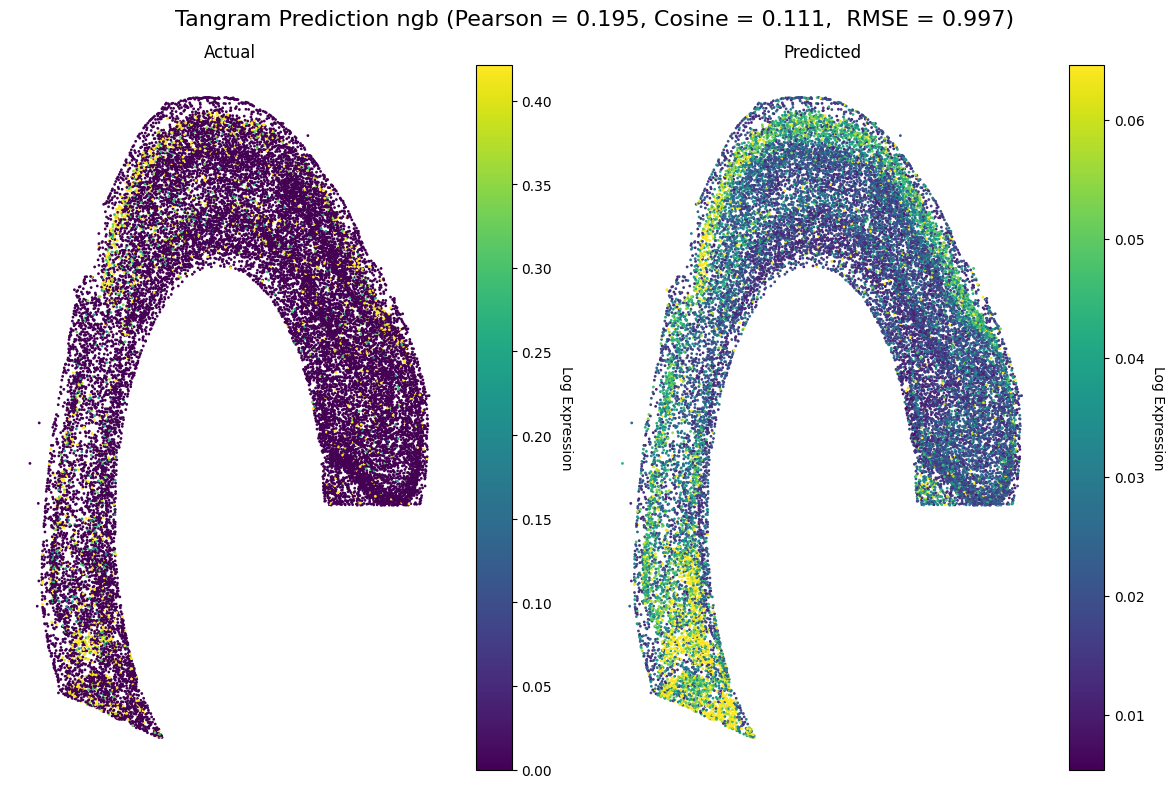

In [25]:
target_gene = "ngb"
target_expn = adata[:, target_gene].X.copy()

# Visualizing predicted and actual expression side by side

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 8))

ax1.axis('off')
cmap = target_expn
cmap[cmap<0] = 0
cmap = np.log1p(cmap)
cmap[cmap > np.percentile(cmap,95)] = np.percentile(cmap,95)
im = ax1.scatter(adata.obs['center_x'],adata.obs['center_y'],s=1,c=cmap, rasterized=True)
# im = ax1.scatter(adata.obsm['spatial'][:,0],adata.obsm['spatial'][:,1],s=1,c=cmap,rasterized=True)
ax1.set_title('Actual', fontsize = 12)

cbar = fig.colorbar(im)
cbar.ax.get_yaxis().labelpad = 15
cbar.ax.set_ylabel('Log Expression', rotation=270)

ax2.axis('off')
cmap = adata.obsm['tangram_predictions'][target_gene].values
cmap[cmap<0] = 0
cmap = np.log1p(cmap)
cmap[cmap > np.percentile(cmap,95)] = np.percentile(cmap,95)
im = ax2.scatter(adata.obs['center_x'],adata.obs['center_y'],s=1,c=cmap, rasterized=True)
ax2.set_title('Predicted', fontsize = 12)

cbar = fig.colorbar(im)
cbar.ax.get_yaxis().labelpad = 15
cbar.ax.set_ylabel('Log Expression', rotation=270)

plt.suptitle(f"Tangram Prediction {target_gene} (Pearson = {tangram_gene_metrics_df.loc[target_gene, 'pearson_r']:.3f}, Cosine = {tangram_gene_metrics_df.loc[target_gene, 'cosine_sim']:.3f},  RMSE = {tangram_gene_metrics_df.loc[target_gene, 'RMSE']:.3f})", fontsize=16)
plt.tight_layout()
plt.show()

In [33]:
# Prepare data
x = adata.obs['center_x']
y = adata.obs['center_y']

actual = adata[:, target_gene].X.copy()
actual[actual < 0] = 0
actual = np.log1p(actual)
actual[actual > np.percentile(actual, 95)] = np.percentile(actual, 95)

predicted = adata.obsm['tangram_predictions'][target_gene].values
predicted[predicted < 0] = 0
predicted = np.log1p(predicted)
predicted[predicted > np.percentile(predicted, 95)] = np.percentile(predicted, 95)

# Use vertical layout for perfect linked zoom
fig = make_subplots(
    rows=2, cols=1,
    shared_xaxes=True,
    shared_yaxes=True,
    subplot_titles=("Actual", "Predicted")
)

# Actual
fig.add_trace(go.Scattergl(
    x=x, y=y,
    mode='markers',
    marker=dict(
        color=actual.flatten(),
        size=2,
        colorscale='Viridis',
        showscale=True,
        colorbar=dict(title='Log Expr', x=1.02)
    ),
    name='Actual'
), row=1, col=1)

# Predicted
fig.add_trace(go.Scattergl(
    x=x, y=y,
    mode='markers',
    marker=dict(
        color=predicted.flatten(),
        size=2,
        colorscale='Viridis',
        showscale=True,
        colorbar=dict(title='Log Expr', x=1.02)
    ),
    name='Predicted'
), row=2, col=1)

# Style layout
fig.update_layout(
    title_text=f"Tangram Prediction {target_gene} (Pearson = {tangram_gene_metrics_df.loc[target_gene, 'pearson_r']:.3f}, Cosine = {tangram_gene_metrics_df.loc[target_gene, 'cosine_sim']:.3f}, RMSE = {tangram_gene_metrics_df.loc[target_gene, 'RMSE']:.3f})",
    height=900,
    width=800,
    paper_bgcolor='black',
    plot_bgcolor='black',
)

# Remove grid, ticks, set white axis lines
fig.update_xaxes(
    showgrid=False, zeroline=False, showticklabels=False, color='white'
)
fig.update_yaxes(
    showgrid=False, zeroline=False, showticklabels=False, color='white'
)

fig.show()



## **6. Testing for Statistical Significance**

In [462]:
actual_matrix = adata[:, tangram_preds.columns].X
actual_matrix = actual_matrix.toarray() if not isinstance(actual_matrix, np.ndarray) else np.array(actual_matrix)
pred_matrix = tangram_preds.values

n_permutations = 1000
n_print = 100
n_cells, n_genes = pred_matrix.shape

observed_pccs = np.array([
    st.pearsonr(pred_matrix[:, i], actual_matrix[:, i])[0]
    for i in range(n_genes)
])

null_pccs = np.zeros((n_permutations, n_genes))
for i in range(n_permutations):
    shuffled_idx = np.random.permutation(n_cells)
    shuffled_preds = pred_matrix[shuffled_idx, :]
    for j in range(n_genes):
        null_pccs[i, j] = st.pearsonr(shuffled_preds[:, j], actual_matrix[:, j])[0]
    if (i + 1) % n_print == 0:
        print(f"Completed {i + 1}/{n_permutations} permutations")

p_values = (np.sum(null_pccs >= observed_pccs[None, :], axis=0) + 1) / (n_permutations + 1)

fdr_results = multipletests(p_values, alpha=0.05, method='fdr_bh')
fdr_corrected_pvals = fdr_results[1]
fdr_significant = fdr_results[0]

tangram_gene_metrics_df["p_value"] = p_values
tangram_gene_metrics_df["imputation_significant"] = p_values < 0.05
tangram_gene_metrics_df["fdr_p_value"] = fdr_corrected_pvals
tangram_gene_metrics_df["imputation_significant_fdr"] = fdr_significant


Completed 100/1000 permutations
Completed 200/1000 permutations
Completed 300/1000 permutations
Completed 400/1000 permutations
Completed 500/1000 permutations
Completed 600/1000 permutations
Completed 700/1000 permutations
Completed 800/1000 permutations
Completed 900/1000 permutations
Completed 1000/1000 permutations


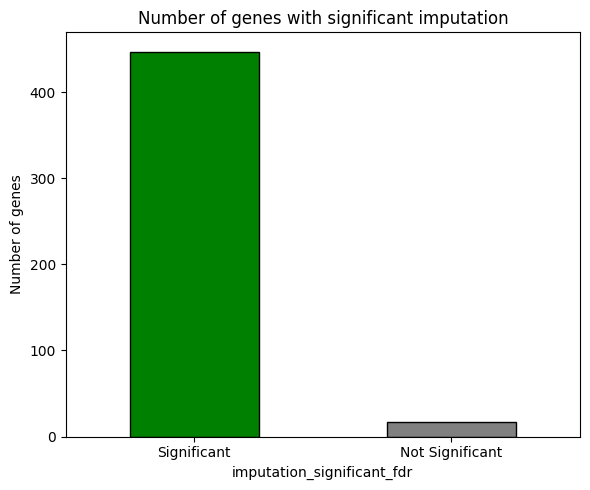

In [468]:
sig_counts = tangram_gene_metrics_df["imputation_significant_fdr"].value_counts().rename({True: 'Significant', False: 'Not Significant'})

plt.figure(figsize=(6, 5))
sig_counts.plot(kind='bar', color=['green', 'grey'], edgecolor='black')
plt.title("Number of genes with significant imputation")
plt.ylabel("Number of genes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

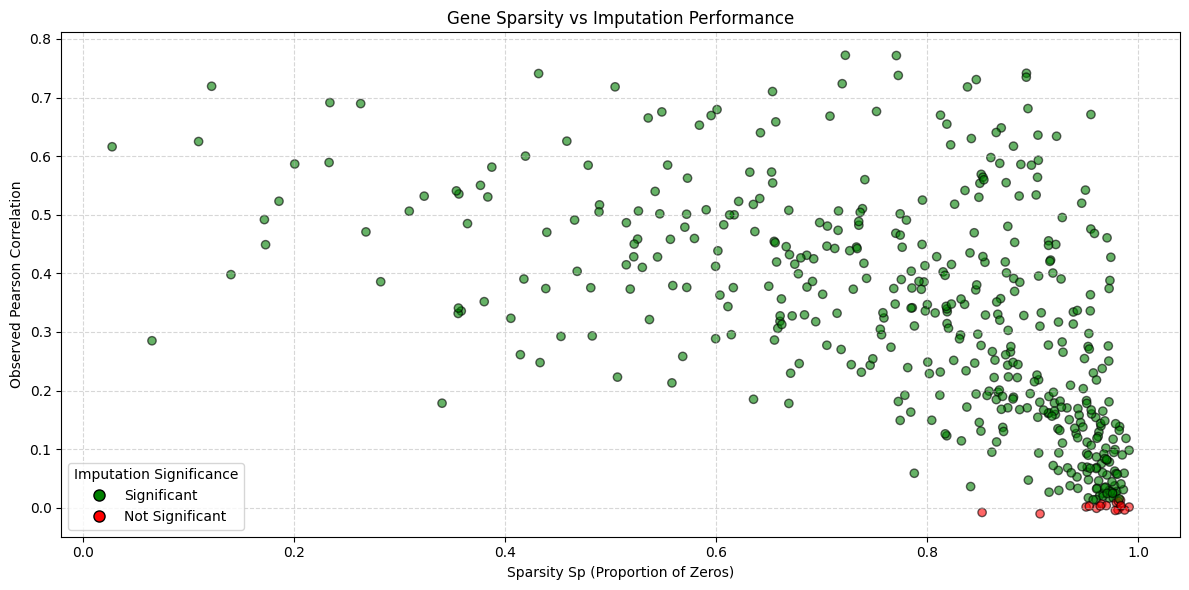

In [470]:
import matplotlib.pyplot as plt

# Choose sparsity from spatial or scRNA-seq (adjust column as needed)
sparsity_col = "sparsity_sp"  # or "sparsity_sc"

# Create the scatter plot
plt.figure(figsize=(12, 6))
colors = tangram_gene_metrics_df["imputation_significant_fdr"].map({True: 'green', False: 'red'})

plt.scatter(
    tangram_gene_metrics_df[sparsity_col],
    tangram_gene_metrics_df["pearson_r"],
    c=colors,
    alpha=0.6,
    edgecolor='k',
    label=None
)

# Labels and aesthetics
plt.xlabel(f"{sparsity_col.replace('_', ' ').title()} (Proportion of Zeros)")
plt.ylabel("Observed Pearson Correlation")
plt.title("Gene Sparsity vs Imputation Performance")

# Custom legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Significant', markerfacecolor='green', markersize=8, markeredgecolor='k'),
    Line2D([0], [0], marker='o', color='w', label='Not Significant', markerfacecolor='red', markersize=8, markeredgecolor='k')
]
plt.legend(handles=legend_elements, title="Imputation Significance")

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [471]:
n_sig = tangram_gene_metrics_df["imputation_significant_fdr"].sum()
print(f"Number of genes with statistically significant imputation: {n_sig}")

Number of genes with statistically significant imputation: 447


The predicted expression for a gene is **no more correlated** with the true expression than a random permutation

## **6. Uncertainty Calibration and Obtaining Prediction Intervals**

In [64]:
adata.obsm["spatial"] = np.vstack([adata.obs["center_x"], adata.obs["center_y"]]).T

### Spatial Graph Construction: `fixed_radius` Method Summary

This method builds a spatial graph by combining k-nearest neighbours (k-NN) with distance-based pruning:

1. **Build k-NN Graph**  
   - For each cell, find its `n_neighbors` (e.g. 15) closest cells using Euclidean distance.  
   - Store connections in two sparse matrices:  
     - `adata.obsp["spatial_connectivities"]`: adjacency (1s for each neighbour pair)  
     - `adata.obsp["spatial_distances"]`: distances between connected cell pairs  

2. **Calculate Distance Threshold (if `radius` is not provided)**  
   - Extract all non-zero distances.  
   - Compute `radius = Q3 + 1.5 × IQR`, where:
     - Q3 = 75th percentile  
     - IQR = Q3 - Q1  

3. **Prune Long Edges**  
   - Set values in both matrices to 0 where distances exceed `radius`.  
   - This removes spatially distant neighbours even if they were among the closest 15.

The result is a robust spatial graph that balances local neighbourhood structure with spatial coherence.


In [68]:
# build spatial graph and calculate adjacency weights

tissue.main.build_spatial_graph(adata, method="fixed_radius", n_neighbors=15)

### Conformal Calibration: `conformalize_spatial_uncertainty` Step Summary

This method estimates uncertainty in spatial gene expression predictions using cell-centred variability and conformal prediction scores, with stratified grouping to improve calibration.

1. **Compute Spatial Uncertainty (Cell-Centred Variability)**  
   - For each cell and gene, measure how different the predicted expression is from that of neighbouring cells.  
   - Weight neighbours using either:
     - Cosine similarity of predicted expression profiles (`exp_cos`)
   - Store results as spatial standard deviations in:
     - `adata.obsm["spage_predictions_uncertainty"]`

2. **Calculate Prediction Errors and Conformal Scores**  
   - Compare predicted values to observed expression for calibration genes (all genes in this case).  
   - Compute:
     - `residual = observed − predicted`
     - `score = |residual| / uncertainty`  
   - Save results in:
     - `adata.obsm["spage_predictions_error"]`
     - `adata.obsm["spage_predictions_score"]`

3. **Group Cells for Stratified Calibration**  
   - To make uncertainty estimation more accurate, group similar gene–cell combinations together.
   - Uses a **two-level k-means clustering** approach (`grouping_method="kmeans_gene_cell"`):
     
     **Step 1: Group Genes**
     - Transpose the predicted expression matrix so each gene becomes a "sample".
     - Standardise gene vectors and optionally reduce dimensions using PCA (`n_pc`).
     - Cluster genes into `k` groups (e.g. 4) using k-means.
     - This separates genes with different expression or variability patterns.

     **Step 2: Group Cells Within Each Gene Group**
     - For each gene cluster, take the submatrix (cells × selected genes).
     - Standardise, optionally run PCA (`n_pc2`), and cluster the cells into `k2` groups (e.g. 2).
     - This allows cells to be grouped **in a gene-context-aware way**, so uncertainty scores reflect local structure.

   - Each cell–gene pair is then assigned a **stratified group ID** (e.g. Group 0, 1, ..., N).
   - These groupings are used to calculate separate conformal score distributions for each group, improving calibration for diverse expression patterns.

   - **Stores results in:**
     - `adata.obsm["spage_predictions_groups"]` → a matrix of group labels (cells × genes)
     - `adata.uns["spage_predictions_kg"]` and `..._kc` → stores the number of gene and cell clusters used


4. **Prepare for Stratified Conformal Prediction**  
   - These scores and groupings are used in downstream steps to assign cell-specific, gene-specific prediction intervals.
   - This allows uncertainty estimates to adapt to both spatial and biological context.

The result is a calibrated, spatially-aware uncertainty measure for each predicted gene expression value.


In [80]:
# build calibration scores

tissue.main.conformalize_spatial_uncertainty(adata, "spage_predictions", calib_genes=adata.var_names,
                                             grouping_method="kmeans_gene_cell", k=4, k2=2)

/Users/Amith/miniconda3/envs/tissue/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
/Users/Amith/miniconda3/envs/tissue/lib/python3.8/site-packages/threadpoolctl.py:1214: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
/Users/Amith/miniconda3/envs/tissue/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change 

In [387]:
tissue.main.conformalize_prediction_interval (adata, "spage_predictions", symmetric=False, calib_genes=adata.var_names,
                                              alpha_level=0.23)

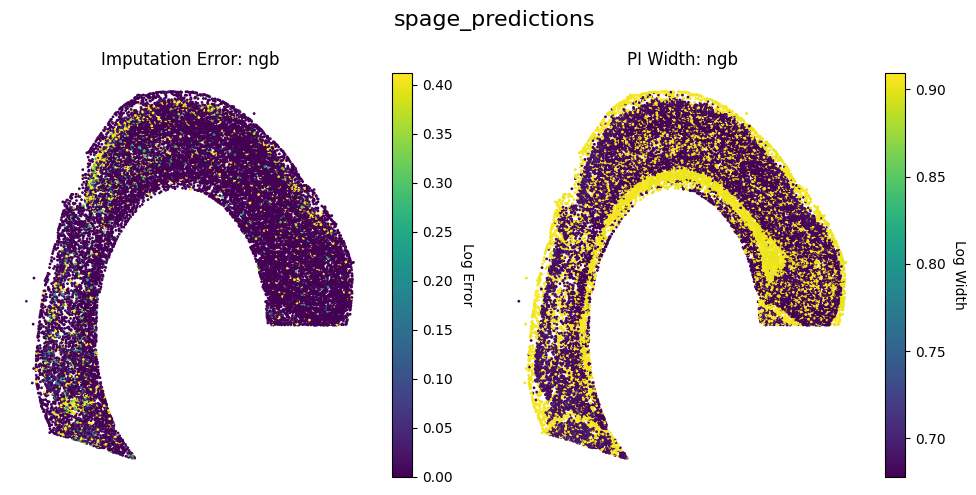

In [393]:
target_gene = "ngb"
target_expn = adata[:, target_gene].X.copy()

m = "spage_predictions"  # Match the key used in conformalize functions
i = np.where(adata.var_names == target_gene)[0]

# Define consistent colour scale range across plots
error = np.abs(target_expn.flatten() - adata.obsm[m][target_gene].values)
interval_width = adata.obsm[m + "_hi"][target_gene].values - adata.obsm[m + "_lo"][target_gene].values

# Combine both for common vmin/vmax
all_vals = np.concatenate((error, interval_width))
all_vals[all_vals < 0] = 0
vmin = np.percentile(np.log1p(all_vals), 0)
vmax = np.percentile(np.log1p(all_vals), 95)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

# Plot imputation error
ax1.axis('off')
cmap1 = np.log1p(error.clip(min=0))
cmap1 = np.clip(cmap1, None, np.percentile(cmap1, 95))
im1 = ax1.scatter(adata.obsm['spatial'][:, 0], adata.obsm['spatial'][:, 1],
                  s=1, c=cmap1, rasterized=True)
ax1.set_title(f'Imputation Error: {target_gene}', fontsize=12)

cbar1 = fig.colorbar(im1, ax=ax1)
cbar1.ax.set_ylabel('Log Error', rotation=270, labelpad=15)

# Plot prediction interval width
ax2.axis('off')
cmap2 = np.log1p(interval_width.clip(min=0))
cmap2 = np.clip(cmap2, None, np.percentile(cmap2, 95))
im2 = ax2.scatter(adata.obsm['spatial'][:, 0], adata.obsm['spatial'][:, 1],
                  s=1, c=cmap2, rasterized=True)
ax2.set_title(f'PI Width: {target_gene}', fontsize=12)

cbar2 = fig.colorbar(im2, ax=ax2)
cbar2.ax.set_ylabel('Log Width', rotation=270, labelpad=15)

plt.suptitle(m, fontsize=16)
plt.tight_layout()
plt.show()
